# data-loading demo
Load prices in the repo's long `MultiIndex(date, ticker)` format. This demo uses the **synthetic** generator so it runs offline; swap in `load_cached()` after running `scripts/fetch.py`.

In [1]:
from quantskills.data import synthetic_prices, to_wide, validate_prices

prices = synthetic_prices(n_assets=10, n_days=500, seed=42)
validate_prices(prices)
prices.head()

open        high         low       close    volume
date       ticker                                                          
2015-01-02 SYN00   100.030444  101.641202   99.649585  101.255678  184740.0
           SYN01   100.269891  101.195652  100.264810  101.190524  666080.0
           SYN02   100.074107  100.384572   98.848979   99.156597  508965.0
           SYN03    99.786733  101.776348   99.517741  101.502730  500858.0
           SYN04   100.091656  100.094091  100.087178  100.089613  499510.0

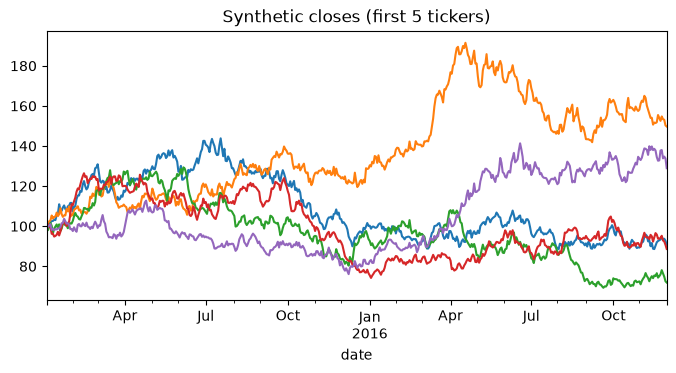

In [2]:
close = to_wide(prices, "close")
close.iloc[:, :5].plot(figsize=(8, 3.5), title="Synthetic closes (first 5 tickers)", legend=False);

## Caching with an injected downloader
Tests and demos never touch the network. `load_prices` takes a `downloader=` so we can show the cache working with a fake source.

In [3]:
import tempfile

import pandas as pd

from quantskills.data import PRICE_COLUMNS, load_prices

calls = []


def fake(ticker, start, end):
    calls.append(ticker)
    idx = pd.bdate_range(start, periods=3)
    return pd.DataFrame({c: [1.0, 2.0, 3.0] for c in PRICE_COLUMNS}, index=idx)


with tempfile.TemporaryDirectory() as d:
    load_prices(["AAA", "BBB"], "2024-01-01", cache_dir=d, downloader=fake)
    df = load_prices(["AAA", "BBB"], "2024-01-01", cache_dir=d, downloader=fake)
print("downloads:", calls)  # second call served from cache
df

downloads: ['AAA', 'BBB']


open  high  low  close  volume
date       ticker                                
2024-01-01 AAA      1.0   1.0  1.0    1.0     1.0
           BBB      1.0   1.0  1.0    1.0     1.0
2024-01-02 AAA      2.0   2.0  2.0    2.0     2.0
           BBB      2.0   2.0  2.0    2.0     2.0
2024-01-03 AAA      3.0   3.0  3.0    3.0     3.0
           BBB      3.0   3.0  3.0    3.0     3.0